# Project 2: Exploratory Data Analysis (EDA)

In this project, you'll work with a large data set on roughly 4,500 NFL games from 2002 to 2019.  The goals of this project are to
* Work with a large data set, including addressing issues in real-world data
* Practice pandas methods for summarizing and exploring data
* Come up with research questions and conjectures
* Use precise statistics and visualizations to discuss your findings.

This project will have three phases.  In the first and second phase, you'll answer scaffolded research questions to practice EDA: you'll sanity check data, deal with some annoyances of real-world data, and answer four research questions.  In the third and final phase, you'll dig deeper into one of these research questions.

## Partner Information
You are allowed to work with a partner on this project.  If you do, only one of you should submit each phase, but that person should add their partner to the submission.


## Background

This data set comes from the r/datasets reddit at [here](https://www.reddit.com/r/datasets/comments/djucb6/nfl_game_stats_scraped_from_espn/), where one user scraped data on over 4,500 NFL games. Let's take a quick look at its first few entries:

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [43]:
# These columns may be read in as dates.  We'll tell pandas to specifically read them in as strings
# since some entries in these columns, like "4-12", can be converted to dates
strcols = ['third_downs_away','third_downs_home', 'fourth_downs_away', 'fourth_downs_home',
           'comp_att_away', 'comp_att_home', 'sacks_away', 'sacks_home', 'penalties_away',
           'penalties_home', 'redzone_away','redzone_home']

nfl_df = pd.read_csv("NFL.csv", dtype = {col: str for col in strcols})
nfl_df.head()

,date,Part_Of_Season,Season,PAT,away,home,first_downs_away,first_downs_home,third_downs_away,third_downs_home,...,redzone_away,redzone_home,drives_away,drives_home,def_st_td_away,def_st_td_home,possession_away,possession_home,score_away,score_home
0,9/5/2002,Regular,2002,2yrd,49ers,Giants,13,21,4-12,9-16,...,0-8,0-6,13,15,0,0,27:32:00,32:28:00,16,13
1,9/8/2002,Regular,2002,2yrd,Jets,Bills,18,26,2-8,7-17,...,0-9,0-8,17,18,2,0,21:06,39:08:00,37,31
2,9/8/2002,Regular,2002,2yrd,Vikings,Bears,19,20,5-13,7-13,...,0-7,0-6,17,17,0,0,31:31:00,28:29:00,23,27
3,9/8/2002,Regular,2002,2yrd,Chargers,Bengals,27,13,6-10,4-11,...,0-7,0-5,11,15,0,0,37:48:00,22:12,34,6
4,9/8/2002,Regular,2002,2yrd,Chiefs,Browns,24,24,5-11,4-11,...,0-10,0-10,20,17,0,0,30:16:00,29:44:00,40,39


We can't see all of the columns (there are too many) but we can start to see a lot of information about 

For each game, the following variables are recorded.  You might note that some columns have a `-` in the middle.  Here's a dictionary of what data is recorded in the spreadsheet:

* date: date of the game
* part\_of\_season: whether the game was a regular-season or playoff game; playoff games include the Superbowl.
* season: the season the game occurred in.  E.g. 2002 is the 2002 season, which spanned from September 5th 2002 through January 26th 2003 (the Superbowl).
* PAT: Whether the PAT was from the 2 yard line (pre-2015) or 15 yard line (after) (If you, like me, are a football novice, it might be good to google PAT to see what this means and why this change might matter!).
* away: name of the away team
* home: name of the home team
* first\_downs\_away: number of first downs of away team
* first\_downs\_home: number of first downs of home team
* third\_downs\_away: number of third down successes-number of third down attempts by the away team (e.g. 4-12 means the away team attempted 12 third downs and made 4 of them)
* third\_downs\_home: number of third down successes-number of third down attempts by the home team
* fourth\_downs\_away: number of fourth down successes-number of fourth down attempts by the away team
* fourth\_downs\_home: number of fourth down successes-number of fourth down attempts by the home team
* fourth\_downs\_home\_attempts: number of attempted fourth down conversions by the home team
* passing\_yards\_away: number of passing yards by the away team
* passing\_yards\_home: number of passing yards by the home team
* rushing\_yards\_away: number of rushing yards by the away team
* rushing\_yards\_home: number of rushing yards by the home team
* total\_yards\_away: number of total yards by the away team
* total\_yards\_home: number of total yards by the home team
* pass\_completions\_away: number of successful pass completions-number of attempted pass completions by the away team
* pass\_completions\_home: number of successful pass completions-number of attempted pass completions by the home team
* sacks\_away\_number: number of times the away  team was sacked
* sacks\_away\_yards: number of yards lost by the away team due to sacks
* sacks\_home\_number: number of times the home  team was sacked
* sacks\_home\_yards: number of yards lost by the home team due to sacks
* rushing\_attempts\_away: number of rushing attempts by the away team	
* rushing\_attempts\_home: number of rushing attempts by the home team	
* fumbles\_away: number of fumbles by the away team
* fumbles\_home: number of fumbles by the home team
* int\_away: number of interceptions thrown by the away team
* int\_home:  number of interceptions thrown by the home team
* turnovers\_away: number of turnovers by the away team
* turnovers\_home: number of turnovers by the home team
* penalties\_away: number of penalties-number of yards due to penalties by the away team
* penalties\_home: number of penalties-number of yards due to penalties by the home team
* redzone\_away: redzone conversions-redzone trips made by the away team
* redzone\_home: redzone conversions-redzone trips made by the home team
* drives\_away: total drives by away team
* drives\_home: total drives by home team
* def\_st\_td\_away: defensive and special team TDs by away team
* def\_st\_td\_home: defensive and special team TDs by home team
* possession\_away: time of possession of away team (in minutes)
* possession\_home: time of possession of home team (in minutes)
* score\_away: away team's final score
* score\_home: home team's final score

Note that Part\_Of\_Seasons, Season, and PAT are variables that I added the the sheet; the rest are pulled from reddit.

<hr style="border: 3px solid #003262;" />
 
## Phase 1, due Wednesday 2/18 at 10pm

<hr style="border: 3px solid #003262;" />

In this first part of the project, you'll begin the EDA process. Below, you will find a series of questions.  For each question, use the subsequent code cell to type relevant pandas code (preserving the code you use for your analysis as well as any output).  You may add additional code cells as you see fit.  Then, when applicable, summarize your answer in prose in the markdown cell. 



**Important Notes**: 
- A few sanity-check tests are provided along the way, but you will want to add your own and to check the output as you go.  For instance, you will add several columns to the `nfl_df` data frame.  Each time you do so, you'll want to check the output of several rows.
- Here and throughout, be sure to use the exact variable names (including capitalization) requested so that your code passes tests.
- As you go, be sure that any lines of code you write will be readable when you submit a pdf.  If you are writing a long line of code, you can enclose it in parenthesis and then split it along multiple lines.  E.g.

```
s3 = (x + x**2/2 + x**3/3
      + x**4/4 + x**5/5
      + x**6/6 + x**7/7
      + x**8/8)
```

### Getting Acquainted with Data

**Question 1**: Use our standard commands (`head`, `sample`, `describe`) and the above data dictionary to explore the data.  Based on the variables and the data dictionary, come up with at least 3 interesting questions that you could study with this data set.  Try to come up with questions that you would not be able to answer with a single Google query (e.g. "which team had the best record in the 2017 season" is probably not an interesting question -- that's immediately Googleable).  

In [44]:
# Code for Question 1 Here
print(nfl_df.head())
print(nfl_df.sample())
print(nfl_df.describe())

       date Part_Of_Season  Season   PAT      away     home  first_downs_away  \
0  9/5/2002        Regular    2002  2yrd     49ers   Giants                13   
1  9/8/2002        Regular    2002  2yrd      Jets    Bills                18   
2  9/8/2002        Regular    2002  2yrd   Vikings    Bears                19   
3  9/8/2002        Regular    2002  2yrd  Chargers  Bengals                27   
4  9/8/2002        Regular    2002  2yrd    Chiefs   Browns                24   

   first_downs_home third_downs_away third_downs_home  ... redzone_away  \
0                21             4-12             9-16  ...          0-8   
1                26              2-8             7-17  ...          0-9   
2                20             5-13             7-13  ...          0-7   
3                13             6-10             4-11  ...          0-7   
4                24             5-11             4-11  ...         0-10   

  redzone_home  drives_away  drives_home  def_st_td_away  def_

1. Does home team have a higher winrate?

2. Do teams that have a better possession win more?

3. How many percentages do winnings teams win more by?

**Question 2**: Now identify 3 interesting games based on the summary statistics in `.describe`.  For instance, you might think "in one game, a team scored 62 points, I wonder what happened?".  Each game should come from a summary statistic in a different column (e.g. don't just look at the 3 games with the highest scores -- those are all based on the same column.  Similarly, don't look at highest home and highest away score as two separate games -- pick columns that are meaningfully distinct).  

Figure out which games those summary statistics correspond to (hint: use a Boolean mask!) and look them up (e.g. on ESPN).  In the text cell below, briefly describe each of those 3 games: what game was it (date and teams), why did you select it (e.g. what statistic made you consider it), and what did your research reveal about what happened in that game (e.g. what factors in the game led to a team scoring 62 points).  This can also help sanity check the data, since you will likely ID and vet some outliers!

In [45]:
# Code for Question 2 Here

# Get summary statistics to identify outliers
stats = nfl_df.describe()
print(stats)

# Game 1: Highest away team score
max_away_score = nfl_df['score_away'].max()
game1 = nfl_df[nfl_df['score_away'] == max_away_score]
print(f"\nGame 1 - Highest away score ({max_away_score}):")
print(game1[['date', 'away', 'home', 'score_away', 'score_home']])

# Game 2: Highest total yards by a team
max_total_yards = nfl_df[['total_yards_away', 'total_yards_home']].max().max()
game2_away = nfl_df[nfl_df['total_yards_away'] == max_total_yards]
game2_home = nfl_df[nfl_df['total_yards_home'] == max_total_yards]
game2 = pd.concat([game2_away, game2_home])
print(f"\nGame 2 - Highest total yards ({max_total_yards}):")
print(game2[['date', 'away', 'home', 'total_yards_away', 'total_yards_home']])

# Game 3: Most turnovers in a game (combined)
nfl_df['total_turnovers'] = nfl_df['turnovers_away'] + nfl_df['turnovers_home']
max_turnovers = nfl_df['total_turnovers'].max()
game3 = nfl_df[nfl_df['total_turnovers'] == max_turnovers]
print(f"\nGame 3 - Most combined turnovers ({max_turnovers}):")
print(game3[['date', 'away', 'home', 'turnovers_away', 'turnovers_home']])

            Season  first_downs_away  first_downs_home  passing_yards_away  \
count  4628.000000       4628.000000       4628.000000         4628.000000   
mean   2010.179343         18.787381         19.778522          219.945765   
std       5.011962          5.042778          4.973541           79.026973   
min    2002.000000          3.000000          3.000000           -7.000000   
25%    2006.000000         15.000000         16.000000          164.000000   
50%    2010.000000         19.000000         20.000000          217.000000   
75%    2015.000000         22.000000         23.000000          273.000000   
max    2019.000000         37.000000         40.000000          516.000000   

       passing_yards_home  rushing_yards_away  rushing_yards_home  \
count         4628.000000         4628.000000         4628.000000   
mean           226.573682          109.735955          117.811582   
std             78.019507           50.843007           52.084850   
min              6.00

### Sanity Checking, Pre-Processing, and Preliminary Investigations

**Question 3**: Since this data was taken from reddit, we should be skeptical about it.  For instance, does it actually contain all games?  Lets see if we can identify any missing or incomplete data.  First, search online to figure out how many NFL games (both regular season and playoff) occur each season.  Then use `.groupby` to get the total number of games from each season in this data set.  You do not need to edit any markdown cells for this question - just create and display the appropriate grouped data frame. 

In [46]:
# Code for Question 3 Here
games_per_season = nfl_df.groupby('Season').size()
games_per_season

Season
2002    267
2003    267
2004    267
2005    267
2006    267
2007    266
2008    267
2009    267
2010    266
2011    266
2012    267
2013    267
2014    267
2015    267
2016    267
2017    267
2018    267
2019     92
dtype: int64

You should notice four anomalies: three seasons seem to be one game short, and one season seems to be missing the vast majority of games.  

**Question 4** Let's see if we can identify if any specific games are missing from the 2007, 2010, and 2011 seasons, or if those seasons were one game short (e.g. due to rule changes, a game being cancelled, etc).  Here's one approach for the 2007 season:
- First, filter down to just games in the 2007 season (you might want to create a new data frame)
- Then group by part of season: was the missing game in the playoffs or the regular season?  (Note that the number of playoff games per season changed in 2020, so make sure you're using the number of regular season and playoff games *before* 2020)
  - If the missing game is from the playoffs, filter down your 2007 season data frame to just playoff games and see which one is missing.  
  - If the missing game is from the regular season, filter down to just regular season games and then group by home/away team.  Which team(s) are missing a regular season game?  Was there a regular season game where those two teams played (Google!)?  If so, what date?  Is that game in the data set?  If not, you've found your missing game!
  
Follow the above process and do some online research.  For the 2007, 2010 and 2011 seasons, is our data set missing a game, or does it have the right number of games?  If the former, what games are missing (give date, home team, and away team).

In [47]:
# Code for Question 4 Here
seasons_to_check = [2007, 2010, 2011]

for season in seasons_to_check:
    print(f"Season {season}")
    season_df = nfl_df[nfl_df["Season"] == season]
    print(season_df["Part_Of_Season"].value_counts())
    
    reg_df = season_df[season_df["Part_Of_Season"] == "Regular"]
    home_counts = reg_df["home"].value_counts()
    away_counts = reg_df["away"].value_counts()
    team_counts = home_counts.add(away_counts, fill_value=0).sort_values()
    
    print("\nTeams with fewer than 16 regular-season games:")
    print(team_counts[team_counts < 16])
    
    print("\nPlayoff games:")
    print(season_df[season_df["Part_Of_Season"] == "Playoff"][["date", "away", "home", "score_away", "score_home"]])

Season 2007
Part_Of_Season
Regular    255
Playoff     11
Name: count, dtype: int64

Teams with fewer than 16 regular-season games:
Cowboys     15
Redskins    15
Name: count, dtype: int64

Playoff games:
           date      away        home  score_away  score_home
1590   1/5/2008  Redskins    Seahawks          14          35
1591   1/5/2008   Jaguars    Steelers          31          29
1592   1/6/2008    Giants  Buccaneers          24          14
1593   1/6/2008    Titans    Chargers           6          17
1594  1/12/2008  Seahawks     Packers          20          42
1595  1/12/2008   Jaguars    Patriots          20          31
1596  1/13/2008  Chargers       Colts          28          24
1597  1/13/2008    Giants     Cowboys          21          17
1598  1/20/2008  Chargers    Patriots          12          21
1599  1/20/2008    Giants     Packers          23          20
1600   2/3/2008    Giants    Patriots          17          14
Season 2010
Part_Of_Season
Regular    255
Playoff    

2007, 2010, and 2011 are each missing one regular‑season game (playoff counts look correct). Based on the team counts and schedule checks:

- **2007:** Missing Redskins at Cowboys on 12/30/2007 (both teams show 15 regular‑season games).  
- **2010:** Missing Vikings at Eagles on 12/28/2010 (the snow‑postponed game; both teams show 15 games).  
- **2011:** Missing Buccaneers at Falcons on 12/11/2011 (both teams show 15 games).

We've now understood the 2007, 2010, and 2011 seasons and honed in on any missing data.  The 2019 season is missing many more games, and that's because this data set is only through the first 6 weeks or so of that season.  

**Question 5** Update nfl_df to drop the 2019 season.  You do not need to edit any markdown cells for this question.

In [48]:
# Code for Question 5 Here
nfl_df = nfl_df[nfl_df["Season"] != 2019].copy()
if "total_turnovers" in nfl_df.columns:
    nfl_df = nfl_df.drop(columns=["total_turnovers"])
nfl_df

,date,Part_Of_Season,Season,PAT,away,home,first_downs_away,first_downs_home,third_downs_away,third_downs_home,...,redzone_away,redzone_home,drives_away,drives_home,def_st_td_away,def_st_td_home,possession_away,possession_home,score_away,score_home
0,9/5/2002,Regular,2002,2yrd,49ers,Giants,13,21,4-12,9-16,...,0-8,0-6,13,15,0,0,27:32:00,32:28:00,16,13
1,9/8/2002,Regular,2002,2yrd,Jets,Bills,18,26,2-8,7-17,...,0-9,0-8,17,18,2,0,21:06,39:08:00,37,31
2,9/8/2002,Regular,2002,2yrd,Vikings,Bears,19,20,5-13,7-13,...,0-7,0-6,17,17,0,0,31:31:00,28:29:00,23,27
3,9/8/2002,Regular,2002,2yrd,Chargers,Bengals,27,13,6-10,4-11,...,0-7,0-5,11,15,0,0,37:48:00,22:12,34,6
4,9/8/2002,Regular,2002,2yrd,Chiefs,Browns,24,24,5-11,4-11,...,0-10,0-10,20,17,0,0,30:16:00,29:44:00,40,39
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4531,1/13/2019,Playoff,2018,15yrd,Chargers,Patriots,22,30,5-13,7-14,...,3-3,5-7,11,13,0,0,21:40,38:20:00,28,41
4532,1/13/2019,Playoff,2018,15yrd,Eagles,Saints,15,25,2-7,8-15,...,1-1,2-2,10,10,0,0,22:10,37:50:00,14,20
4533,1/20/2019,Playoff,2018,15yrd,Rams,Saints,19,19,6-16,6-14,...,2-4,2-5,11,12,0,0,32:36:00,30:41:00,26,23
4534,1/20/2019,Playoff,2018,15yrd,Patriots,Chiefs,36,18,13-19,4-9,...,4-5,3-3,12,11,0,0,43:59:00,20:53,37,31


In [49]:
# Run this cell to check that nfl_df has the right size
# If you have added any superfluous columns, drop them so that this test passes
try:
    if nfl_df.size==4536*42:
        print("Public test for 5 passed")
    else:
        print("Public test for 5 FAILED")
except:
    print("Public test for 5 FAILED")


Public test for 5 passed


One important (and sometimes tedious) part of EDA is making a data set amenable to analysis.  Here, for instance, lets look at our penalties columns:

In [50]:
nfl_df["penalties_away"].loc[0:4]

0     5-29
1    10-90
2     8-52
3     4-39
4     9-87
Name: penalties_away, dtype: object

This column gives two pieces of data: the number of penalties for the away team that game and the number of yards lost due to penalties for the away team that game.  For instance, in game 0, the away team got 5 penalties and lost 29 total yards due to penalties.  There are several columns like this, so lets write a short function that will allow us to split a string like `5-29` into its constituent floats.

**Question 6**: Write a function `first` in a string of the form `"number1-number2"` and returns `number1` as a float.  Then write a function `second` that takes the same input and returns `number2` as a float.  You do not need to edit any markdown cells for this question.

In [51]:
# Code for Question 6 here

def first(data):
    return float(data.split('-')[0])
    
def second(data):
    return float(data.split('-')[1])
    
    
try:
    [x, y] = [first("5-29"), second("5-29")]
    if x==5 and y==29 and type(x)==float and type(y)==float:
        print("Public test for 6 passed")
    else:
        print("Public test for 6 FAILED")
except:
    print("Public test for 6 FAILED")    

Public test for 6 passed


**Question 7a**: In the next part of this question (7b), we'll add a column telling us whether the home or away team won -- and we'll also apply the functions you just wrote to create additional new columns.  Before we do that, though, we should sanity check to see if there were any ties.  Write code that will identify if any games ended in a tie, and then briefly indicate how many (if any) games ended in a tie.  Be sure to use pandas methods, like filtering, grouping, creating/modifying columns, merging, etc, rather than iterating through a data frame.

In [52]:
# Code for Question 7a here
ties = nfl_df[nfl_df['score_away'] == nfl_df['score_home']]
print(f"Number of games that ended in a tie: {len(ties)}")
print(ties[['date', 'away', 'home', 'score_away', 'score_home']])

Number of games that ended in a tie: 9
            date      away       home  score_away  score_home
135   11/10/2002   Falcons   Steelers          34          34
1747  11/16/2008    Eagles    Bengals          13          13
2810  11/11/2012      Rams      49ers          24          24
3099  11/24/2013   Vikings    Packers          26          26
3279  10/12/2014  Panthers    Bengals          37          37
3840  10/23/2016  Seahawks  Cardinals           6           6
3843  10/30/2016  Redskins    Bengals          27          27
4270    9/9/2018  Steelers     Browns          21          21
4288   9/16/2018   Vikings    Packers          29          29


9 games ended in a tie.

**Question 7b**: Add the following columns to your data set, making sure that they are stored as numerical (rather than categorical) variables.  To get your first four columns, use the `apply` method for data frames and the functions you wrote in question 6 (you might want to Google the `apply` method).
* `num_penalties_away`, the number of penalties the away team got each game (e.g. this should be 5 for row 0)
* `num_penalties_home`, the number of penalties that the home team got each game
* `yards_penalties_away`, the yards the away team lost due to penalties (e.g. this should be 29 for row 0)
* `yards_penalties_home`, the yards the home team lost due to penalties


Also add a column `winner` that should store categorical data: either `"Home"`, `"Away"`, or `"Tie"` (as a string), depending on whether the home or away team won or the game ended in a tie.  For this, use `np.where` (potentially twice!).

Be sure that you use the exact same column names/conventions as indicated above so that any tests run correctly.  If you add any additional columns that are superfluous, please be sure to delete them so the tests below pass. 

You do not need to edit any markdown cells for this question.

In [53]:
# Code for Question 7b here
nfl_df["num_penalties_away"] = nfl_df["penalties_away"].apply(first)
nfl_df["num_penalties_home"] = nfl_df["penalties_home"].apply(first)
nfl_df["yards_penalties_away"] = nfl_df["penalties_away"].apply(second)
nfl_df["yards_penalties_home"] = nfl_df["penalties_home"].apply(second)

nfl_df["winner"] = np.where(
    nfl_df["score_home"] > nfl_df["score_away"],
    "Home",
    np.where(nfl_df["score_home"] < nfl_df["score_away"], "Away", "Tie"),
)
try:
    if (nfl_df.size == 4536*47 and nfl_df.loc[0, "num_penalties_away"] == 5 
        and nfl_df.loc[0, "yards_penalties_away"] == 29
        and nfl_df.loc[0, "yards_penalties_home"] == 80
        and nfl_df.loc[0, "num_penalties_home"] == 10
        and nfl_df.loc[0, "winner"] == "Away"
        and nfl_df.loc[2, "winner"] == "Home"       
       ):
        print("Public test for 7 passed")
    else:
        print("Public test for 7 FAILED")
except:
    print("Public test for 7 FAILED")  


Public test for 7 passed


In [54]:
# Run, but do not edit, this cell

nfl_df[["date", "away", "home", "score_home", "score_away", "num_penalties_home", "num_penalties_away", 'yards_penalties_home', 'yards_penalties_away', 'winner']].head(10)

,date,away,home,score_home,score_away,num_penalties_home,num_penalties_away,yards_penalties_home,yards_penalties_away,winner
0,9/5/2002,49ers,Giants,13,16,10.0,5.0,80.0,29.0,Away
1,9/8/2002,Jets,Bills,31,37,10.0,10.0,82.0,90.0,Away
2,9/8/2002,Vikings,Bears,27,23,4.0,8.0,33.0,52.0,Home
3,9/8/2002,Chargers,Bengals,6,34,9.0,4.0,57.0,39.0,Away
4,9/8/2002,Chiefs,Browns,39,40,4.0,9.0,38.0,87.0,Away
5,9/8/2002,Falcons,Packers,37,34,3.0,4.0,15.0,82.0,Home
6,9/8/2002,Eagles,Titans,27,24,6.0,10.0,50.0,113.0,Home
7,9/8/2002,Lions,Dolphins,49,21,4.0,6.0,54.0,68.0,Home
8,9/8/2002,Cardinals,Redskins,31,23,7.0,1.0,56.0,5.0,Home
9,9/8/2002,Ravens,Panthers,10,7,6.0,6.0,35.0,45.0,Home


In [55]:
# Run, but do not edit, this cell

nfl_df["winner"].value_counts()

winner
Home    2600
Away    1927
Tie        9
Name: count, dtype: int64

**Question 7c:** How does the mean number of penalties compare for playoff and regular season games?  How does the median number of penalties compare for playoff and regular season games? Give precise summary statistics in your answer.  Then do some research to briefly give reasons for any trend you observe.

In [56]:
# Code for Question 7c here
penalty_summary = nfl_df.groupby("Part_Of_Season")[["num_penalties_home", "num_penalties_away"]].agg(
    ["mean", "median"]
)
penalty_summary["mean_total_penalties"] = (
    penalty_summary[("num_penalties_home", "mean")]
    + penalty_summary[("num_penalties_away", "mean")]
)
penalty_summary["median_total_penalties"] = (
    penalty_summary[("num_penalties_home", "median")]
    + penalty_summary[("num_penalties_away", "median")]
)
penalty_summary

num_penalties_home        num_penalties_away         \
                             mean median               mean median   
Part_Of_Season                                                       
Playoff                  5.347594    5.0           5.454545    5.0   
Regular                  6.225569    6.0           6.610485    6.0   

               mean_total_penalties median_total_penalties  
                                                            
Part_Of_Season                                              
Playoff                   10.802139                   10.0  
Regular                   12.836054                   12.0

Regular seasons tend to have higher statistics when it comes to mean and median of the number of penalties.

### Research Question 1: Home Team Advantage

**Question 8** OK!  Now that we've sorted out some of our data, lets start exploring research questions.  One phenomenon is the *home team advantage*: the team playing at home might gain some advantage for several reasons:
* They generally have more of the crowd on their side
* They are playing on familiar turf
* They didn't have to travel

Lets see if there is evidence of a home field advantage. Use pandas methods and precise statitics to answer the following questions:
* What percent of games in our data set were won by the home team?  Is it bigger than 50%?
* How does the mean score of the home team compare to the mean score of the away team, averaged over all games in the data set?  Some classic estimates suggest that, e.g., the home team advantage might be translate to a 3 point advantage.
* Is there any evidence to suggest that the away team gets more penalties than the home team?

In [57]:
# Code for Question 8 Here
home_win_pct = (nfl_df["winner"] == "Home").mean() * 100
home_mean_score = nfl_df["score_home"].mean()
away_mean_score = nfl_df["score_away"].mean()
mean_score_diff = home_mean_score - away_mean_score

penalty_means = nfl_df[["num_penalties_home", "num_penalties_away"]].mean()
penalty_diff = penalty_means["num_penalties_away"] - penalty_means["num_penalties_home"]

print(f"Home win percentage: {home_win_pct:.2f}%")
print(f"Mean score - Home: {home_mean_score:.2f}, Away: {away_mean_score:.2f}, Diff: {mean_score_diff:.2f}")
print(f"Mean penalties - Home: {penalty_means['num_penalties_home']:.2f}, Away: {penalty_means['num_penalties_away']:.2f}, Diff: {penalty_diff:.2f}")

Home win percentage: 57.32%
Mean score - Home: 23.33, Away: 20.78, Diff: 2.54
Mean penalties - Home: 6.19, Away: 6.56, Diff: 0.37


- Consistent home field advantage.
- Home field advantage translates to approximately a 3-point scoring advantage.
- Away teams receive slightly more penalties than home teams, which could contribute to home field advantage (though the effect appears modest).

Lets see if there is anything different about playoff games.

**Question 9**: Use pandas methods and precise data to answer the following questions:
* What percent of playoff games were won by the home team?
* Amoung playoff games, how did the mean score of the home team compare to the mean score of the away team?

Then do some research: why might the home team advantage be stronger in the playoffs?

In [58]:
# Code for Question 9 Here
playoff_df = nfl_df[nfl_df["Part_Of_Season"] == "Playoff"]

playoff_home_win_pct = (playoff_df["winner"] == "Home").mean() * 100
playoff_home_mean = playoff_df["score_home"].mean()
playoff_away_mean = playoff_df["score_away"].mean()
playoff_mean_diff = playoff_home_mean - playoff_away_mean

print(f"Playoff home win percentage: {playoff_home_win_pct:.2f}%")
print(
    f"Playoff mean score - Home: {playoff_home_mean:.2f}, "
    f"Away: {playoff_away_mean:.2f}, Diff: {playoff_mean_diff:.2f}"
)

Playoff home win percentage: 59.89%
Playoff mean score - Home: 25.24, Away: 21.27, Diff: 3.97


- **Home win % in playoffs:** 59.89% (higher than 50%).  
- **Mean playoff scores:** Home 25.24 vs Away 21.27 (home +3.97 points).  
- **Why stronger in playoffs:** Higher seeds host more games, so better teams play at home; crowd/noise and reduced travel also matter, and single-elimination can magnify small advantages.


### Research Question 2: Team Stats

Right now, we have a dataframe where the samples are individual games.  We'll now dig into team performance.  However, this data set is not immediately amenable to that kind of analysis.

**Question 10** Add columns `win_team` and `lose_team` that store the winning and losing team.  If a game ended in a tie, store `TIE` for both. Be sure to use pandas methods, like grouping, creating/modifying columns, merging, etc, rather than iterating through a data frame.  Hint: consider using `.apply` to apply a lambda function with `if/else` logic; you may need to set the axis to be 1 to apply it to columns.  You might want to also spot check your work by, e.g., You do not need to edit any markdown cells for this question.

In [59]:
# Code for Question 10 Here
nfl_df["win_team"] = np.where(
    nfl_df["winner"] == "Home",
    nfl_df["home"],
    np.where(nfl_df["winner"] == "Away", nfl_df["away"], "TIE"),
)

nfl_df["lose_team"] = np.where(
    nfl_df["winner"] == "Home",
    nfl_df["away"],
    np.where(nfl_df["winner"] == "Away", nfl_df["home"], "TIE"),
)

In [60]:
# Run, but do not edit, this cell

nfl_df[["date", "away", "home", "score_away", "score_home", "win_team", "lose_team"]].head()

,date,away,home,score_away,score_home,win_team,lose_team
0,9/5/2002,49ers,Giants,16,13,49ers,Giants
1,9/8/2002,Jets,Bills,37,31,Jets,Bills
2,9/8/2002,Vikings,Bears,23,27,Bears,Vikings
3,9/8/2002,Chargers,Bengals,34,6,Chargers,Bengals
4,9/8/2002,Chiefs,Browns,40,39,Chiefs,Browns


**Question 11**: Let's now start looking at team statistics.  Create a DataFrame `team_df` with `team` as the index and one column storing `total_games` (the total games played by that team in the data set, including both regular-season and playoff games) of each NFL team. What team had the largest number of games played and which team had the smallest number of games played?  Give both teams and the number of games they played, and then briefly describe why better teams tend to have a higher number of games played (you might do some research on how the playoffs work here!).

Hint: you might consider making and merging some grouped tables!  First, try to make a `groupby` table that gets the number of home games each team played.  Then think about finding another one for away games and merging (here, merging on index is useful, and you might check Google to review syntax for how to merge on index).  If you add any temporary columns or superfluous rows, be sure to drop them. Be sure to use pandas methods, like grouping, creating/modifying columns, merging, etc, rather than iterating through a data frame. You do not need to edit any markdown cells for this question.

In [61]:
# Code for Question 11 Here
home_games = nfl_df.groupby("home").size().rename("home_games")
away_games = nfl_df.groupby("away").size().rename("away_games")

team_df = pd.concat([home_games, away_games], axis=1).fillna(0)
team_df["total_games"] = team_df["home_games"] + team_df["away_games"]
team_df = team_df[["total_games"]].astype(int)
team_df.index.name = "team"

In [62]:
# Run, but do not edit, this cell
print(len(team_df))
team_df.head()

32


,total_games
team,
49ers,282
Bears,279
Bengals,279
Bills,273
Broncos,286


*Type your answer to Question 11 in this cell*

<hr style="border: 3px solid #003262;" />
 
You have now made it through phase 1!  You are welcome to continue working on the questions below, which will be part of phase 2, but you only have to have the above completed for phase 1!

<hr style="border: 3px solid #003262;" />

### Phase 1 Submission Instructions

For Phase 1, you will submit to **two** separate Gradescope assignments: a PDF and your Jupyter notebook.  These submission instructions are thus similar, but slightly different, than ones in the past -- so read carefully.
1. Restart the Kernel (e.g. Kernel --> Restart) and run all cells above this one (e.g. Cell --> Run All Above). 
2. Make sure that all of the above cells run without error, including the cells that say `# Run, but do not edit, this cell`.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.
5. Upload that PDF to `Project 2 Phase 1: PDF Submission` on Gradescope.  Tag all pages with the relevant question, and if you worked with a partner, add them to your submission.
6.  Upload your Project 2 Jupyter notebook to `Project 2 Phase 1: Jupyter Submission` on Gradescope.  If you worked with a partner, add them to your submission.  Look at the code you uploaded and verify that you submitted a complete Jupyter notebook, with answers to the above questions / cells run.  You do not (and should not) zip anything, include data sources, etc -- just upload your .ipynb file.

As always, if you run into any issues, please be sure to send me documentation of your completed work (e.g. a completed Jupyter notebook) before the deadline.

### Phase 1 Grading Information.

Meeting the Phase 1 checkpoint is worth 15 points of your submission.  You will get 2 automatic autograder points for submitting your Jupyter notebook (note that the autograder is only checking that you've included a Jupyter notebook file -- you should independently verify that it actually has the right input and output).  This submission is a backup so that I can see what code was completed on time.

This phase will primarily be graded on completeness: I will not carefully check your code or your written answers, but will verify that you have responded to all questions with reasonably polished answers, that you have passed the provided tests, and that you have written appropriate code.  Your work will be checked on completeness with your phase 2 submission -- so if you discover that you made errors in the above, you are welcome to correct them for your future submissions. 


<hr style="border: 3px solid #003262;" />
 
## Phase 2: Due Wednesday 2/25 at 10pm

<hr style="border: 3px solid #003262;" />


In this phase, you'll continue working on scaffolded analysis!  If you're picking this back up, be sure to rerun the above cells.

**Question 12**: What are the top 3 teams with the most penalties, and what are the top 3 teams with the most penalties per game (i.e. the team's total number of penalties divided by the team's total number of games)?  Be sure to give the specific numbers of penalties and penalties per game for each of these 6 teams.  Which do you think is more informative for understanding which teams might play the "dirtiest"?

*Note*: You may run into errors if you repeatedly run a code cell that operates on a data frame (e.g. if you merge a data frame and create new columns, then re-run the cell and it tries to again merge it).  If you run into issues, you may want to re-run the cell from where you first created `team_df` and do all operations (merges, drops, adding columns, etc) exactly once.

In [63]:
# Code for Question 12 Here
# Calculate total penalties for each team
home_penalties = nfl_df.groupby("home")[["num_penalties_home"]].sum().rename(columns={"num_penalties_home": "penalties"})
away_penalties = nfl_df.groupby("away")[["num_penalties_away"]].sum().rename(columns={"num_penalties_away": "penalties"})

total_penalties = pd.concat([home_penalties, away_penalties]).groupby(level=0).sum()
team_df["total_penalties"] = total_penalties
team_df["penalties_per_game"] = team_df["total_penalties"] / team_df["total_games"]

# Top 3 teams with most penalties
top_3_most_penalties = team_df.nlargest(3, "total_penalties")[["total_penalties"]]
print("Top 3 teams with most penalties:")
print(top_3_most_penalties)

# Top 3 teams with most penalties per game
top_3_penalties_per_game = team_df.nlargest(3, "penalties_per_game")[["penalties_per_game"]]
print("\nTop 3 teams with most penalties per game:")
print(top_3_penalties_per_game)

Top 3 teams with most penalties:
         total_penalties
team                    
Raiders           2199.0
Ravens            1973.0
Rams              1956.0

Top 3 teams with most penalties per game:
            penalties_per_game
team                          
Raiders               7.967391
Rams                  7.010753
Buccaneers            6.822464


The top 3 teams with most penalties are Raiders, Ravens, and Rams; but the top 3 teams with most penalties per game are Raiders, Rams, and Buccaneers. For understanding which teams might play the “dirtiest,” penalties per game is more informative than total penalties because it adjusts for number of games played and reflects a more consistent behavior.

Our `team_df` stores one measure of team success (how many games they played).  Let's add some more!

**Question 13**: Add the following columns to `team_df`
* `rs_win_pct`: Regular Season Win Percent amoung games without ties (e.g. if a team won 10 regular season games, lost 15, and tied once, their regular season win percent amoung games without ties would be 10/(10+25)=0.4; here, you'd store 0.4 rather than 40\%)
* `playoff_aps`: Playoff Appearances, i.e. the number of seasons in which each team made it to playoffs (note: this is NOT the number of playoff games.  If a team played 2 playoff games in the 2010 season and 1 in the 2011 season, this counts as two playoff appearances).  This is a bit tricky, so here is my suggested approach: 
  * First, make a filtered dataframe that just includes playoff games and two columns: `Season` and `away`
  * Second, make a filtered dataframe that just includes playoff games and two columns: `Season` and `home`
  * Rename the `away`/`home` columns to be the same name.
  * Vertically stack these two dataframes (use `pd.concat`)
  * Use `.drop_duplicates` so that you have one unique entry per season/team combo
  * Use an appropriate `groupby` call to get the number of playoff appearances per team
  
What were the best 3 teams according to each of our three measures (`total_games`, `rs_win_pct`, and `playoff_aps`)? 

In [64]:
# Code for Question 13 Here
# Calculate regular season win percentage
rs_games = nfl_df[nfl_df["Part_Of_Season"] == "Regular"].copy()
rs_wins = rs_games[rs_games["winner"] != "Tie"].groupby("win_team").size()
rs_total = rs_games[rs_games["winner"] != "Tie"].groupby(
    lambda i: rs_games.loc[i, "away"] if rs_games.loc[i, "winner"] == "Away" 
              else rs_games.loc[i, "home"]
).size()

rs_results = []
for team in team_df.index:
    team_games = rs_games[((rs_games["away"] == team) | (rs_games["home"] == team)) & (rs_games["winner"] != "Tie")]
    wins = len(team_games[team_games["win_team"] == team])
    total = len(team_games)
    rs_results.append({"team": team, "rs_win_pct": wins / total if total > 0 else 0})

rs_df = pd.DataFrame(rs_results).set_index("team")
team_df["rs_win_pct"] = rs_df["rs_win_pct"]

# Calculate playoff appearances
playoff_away = nfl_df[nfl_df["Part_Of_Season"] == "Playoff"][["Season", "away"]].rename(columns={"away": "team"})
playoff_home = nfl_df[nfl_df["Part_Of_Season"] == "Playoff"][["Season", "home"]].rename(columns={"home": "team"})
playoff_apps = pd.concat([playoff_away, playoff_home]).drop_duplicates().groupby("team").size()
team_df["playoff_aps"] = playoff_apps
team_df["playoff_aps"] = team_df["playoff_aps"].fillna(0).astype(int)

In [65]:
# Run, but do not edit, this cell
team_df[['total_games', 'rs_win_pct', 'playoff_aps']].sort_values("playoff_aps", ascending=False).head()

,total_games,rs_win_pct,playoff_aps
team,,,
Patriots,309,0.768382,15
Colts,297,0.639706,13
Packers,294,0.603704,12
Seahawks,296,0.575646,12
Steelers,294,0.646840,11


The best 3 teams are Patriots, Colts, and Packers

**Question 14**: Run the following code cells.  What does the `.corr()` method do?  What plots do you see in `scatter_matrix(team_df)`? What pair of variables in `team_df` has the highest correlation?  What might explain why the correlation is so strong?

In [66]:
team_df[['total_games', 'rs_win_pct', 'playoff_aps']].corr()

,total_games,rs_win_pct,playoff_aps
total_games,1.000000,0.909853,0.954383
rs_win_pct,0.909853,1.000000,0.933270
playoff_aps,0.954383,0.933270,1.000000


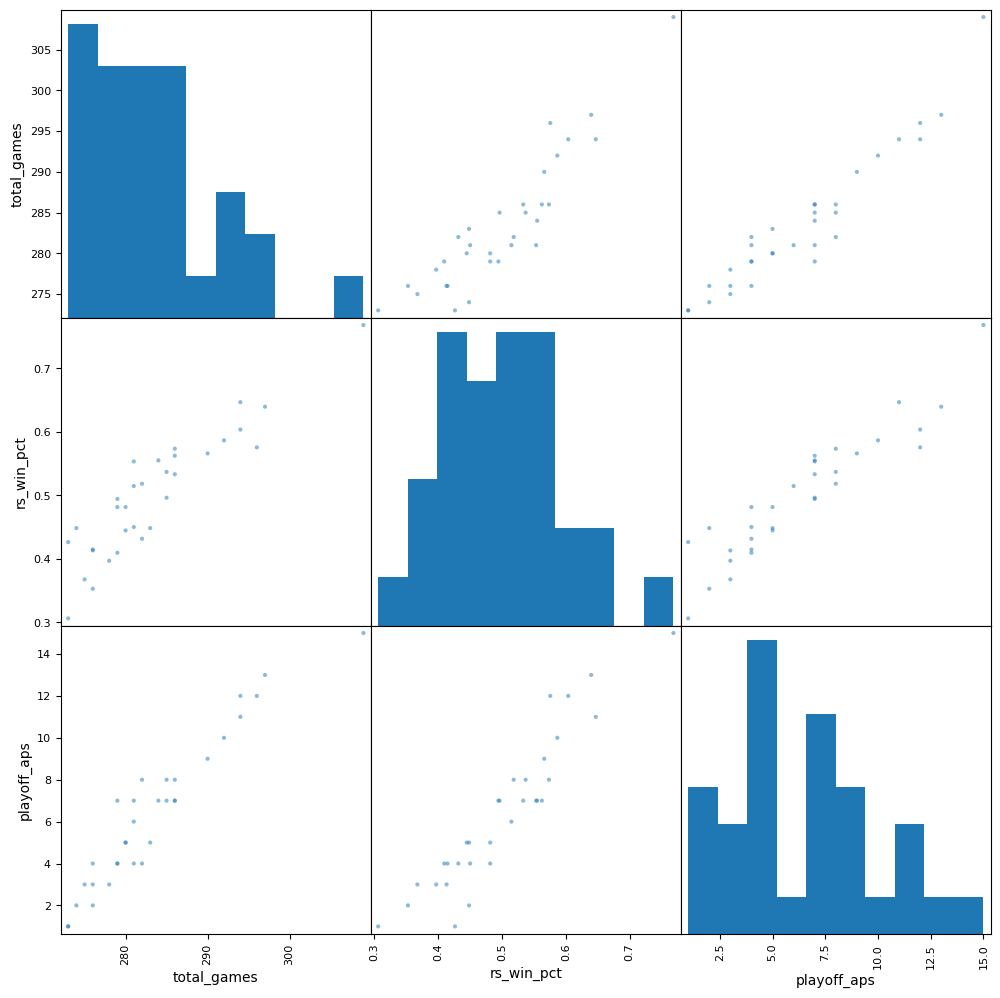

In [67]:
from pandas.plotting import scatter_matrix

scatter_matrix(team_df[['total_games', 'rs_win_pct', 'playoff_aps']], figsize=(12, 12))
plt.show()

The `.corr()` method calculates the pairwise correlation coefficients between numeric columns in a DataFrame, showing how strongly variables are linearly related (values range from -1 to 1).

In `scatter_matrix(team_df)`, we see a grid of plots: scatter plots in off-diagonal cells showing relationships between pairs of variables, and histograms on the diagonal showing the distribution of each variable.

The pair with the highest correlation is **`total_games` and `playoff_aps`** (playoff appearances). This makes sense as better teams (1) play all regular season games regardless of record, but (2) additionally play more playoff games by making deeper playoff runs. Teams that consistently make the playoffs accumulate more total games over the 2002-2018 period. Conversely, weaker teams with fewer playoff appearances have fewer total games despite playing the same number of regular season games each year they competed.

**Question 15**: Let's look at one more notion of team success: superbowl appearances, i.e. the number of seasons in which each team made it to the Superbowl.

Write pandas code to determine the number of times each team made it to the superbowl.  Hint: you can use a process similar to getting playoff appearances, noting that the superbowl is the **last** playoff game of each season (and yes, that bolding is a direct hint to an aggregation method that might help!).  You do not, however, have to merge this into `team_df`.  Be sure to use pandas methods, like grouping, creating/modifying columns, merging, etc, rather than iterating through a data frame.

What 3 teams had the most superbowl appearances during this time and how many appearances did they have?

In [68]:
# Code for Question 15 Here
# Filter to playoff games only
playoff_df = nfl_df[nfl_df["Part_Of_Season"] == "Playoff"].copy()

# Get the last playoff game (Superbowl) for each season
superbowl_games = playoff_df.groupby("Season").tail(1)

# Get teams that appeared in the Superbowl (both home and away)
sb_away = superbowl_games[["Season", "away"]].rename(columns={"away": "team"})
sb_home = superbowl_games[["Season", "home"]].rename(columns={"home": "team"})

# Combine and count unique season appearances per team
sb_appearances = pd.concat([sb_away, sb_home]).drop_duplicates().groupby("team").size().sort_values(ascending=False)

print("Top 3 teams with most Superbowl appearances:")
print(sb_appearances.head(3))

Top 3 teams with most Superbowl appearances:
team
Patriots    8
Steelers    3
Seahawks    3
dtype: int64


The top 3 teams with the most superbowl appearances are : Patriots (8 times), Steelers and Seahawks (both 3 times)

### Research Question 3: NFL Score Distributions

Some Bucknell students made some news for their research on *NFL Scorigamis*.  An NFL Scorigami occurs when a game ends in a new, never-before-seen NFL score.  For instance, as of February 2026, no NFL game has ended 36-23.  If a game were to end 36-23, that would be a scorigami.  NFL Scorigamis have a cult-like following with hundreds of thousands of followers.  Work by Bucknell students Liam Moyer and Jameson Railey appeared in [this Atlantic article](https://www.theatlantic.com/science/2025/12/nfl-scorigami-36-23/685136/?gift=aJhCvy08JPGK8eWqeqfR8MBSngvNrLuH_nSwfFkr6zI&utm_source=copy-link&utm_medium=social&utm_campaign=share), and the full (published!) paper written by the students is [here](https://ieeexplore.ieee.org/stamp/stamp.jsp?arnumber=10838764&casa_token=TRfIdvpAlesAAAAA:cwbjOKCWxPQ_PYy887sGYpQ2ZP97U5Vqj-Y3myn7ohTIEf_qXncePnDdSJ9JsYsEPvlb-Mva&tag=1).  

In this research question, we'll look at NFL scoring distributions.

**Question 16**: We'd like to keep track of each pair of NFL scores that has occured.  Create two new columns in `nfl_df`: `win_score` and  `lose_score`, containing the scores of the winning and losing team.  If a game ends in a tie, that score should be set as both the winning and losing score. 

What is the most common winning score?  What is the most common losing score?

In [69]:
# Code for Question 16 Here
nfl_df["win_score"] = np.where(
    nfl_df["winner"] == "Home",
    nfl_df["score_home"],
    np.where(nfl_df["winner"] == "Away", nfl_df["score_away"], nfl_df["score_home"])
)

nfl_df["lose_score"] = np.where(
    nfl_df["winner"] == "Home",
    nfl_df["score_away"],
    np.where(nfl_df["winner"] == "Away", nfl_df["score_home"], nfl_df["score_away"])
)

most_common_win = nfl_df["win_score"].mode()[0]
most_common_lose = nfl_df["lose_score"].mode()[0]

print(f"Most common winning score: {most_common_win}")
print(f"Most common losing score: {most_common_lose}")

Most common winning score: 27
Most common losing score: 17


In [70]:
# Run, but do not edit, this cell
nfl_df[["win_score", "lose_score"]].head()

,win_score,lose_score
0,16,13
1,37,31
2,27,23
3,34,6
4,40,39


Most common winning score is 27, and most common losing score is 17

NFL Scorigamis, however, are concerned with pairwise scores.  Let's look at the most common pairwise scores.

**Question 17** Make a pivot table, `scorigami_pivot`, with the columns corresponding to the winning team score and the rows corresponding to the losing team's score.  Use the option `fill_value=0` (which will fill in scores that have never happened before with 0s, rather than NaNs).  Note: this will be way too big to visualize by itself.  Then run the subsequent code cells to generate a scorigami-like heatmap.  This will be similar to what you can find [here](https://nflscorigami.com/), if you show gradient and imagine rotating the plot (though that link is based on all NFL games ever, while our data is only based on the 2002-2018 seasons).

Why are there no "boxes" appearing above the diagonal?

In [71]:
# Code for Question 17 Here

scorigami_pivot = nfl_df.pivot_table(
    index='lose_score',
    columns='win_score',
    aggfunc='size',
    fill_value=0
)
scorigami_pivot

win_score,3,6,7,8,9,10,11,12,13,14,...,51,52,53,54,55,56,57,58,59,62
lose_score,,,,,,,,,,,,,,,,,,,,,
0,1,3,0,1,2,2,0,2,1,1,...,0,1,0,0,0,0,0,1,1,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,3,2,0,4,11,0,0,10,6,...,0,1,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
6,0,1,4,0,9,13,0,2,13,4,...,0,0,0,0,0,0,0,0,0,0
7,0,0,0,0,6,7,0,6,10,5,...,0,1,0,0,1,0,0,0,0,1
8,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,4,0,7,11,5,...,0,0,0,0,0,0,0,0,0,0
10,0,0,0,0,0,0,1,7,44,11,...,0,0,0,0,0,2,0,0,0,0


In [72]:
# Run, but do not edit, this cell
scorigami_pivot.loc[0:7, 3:14]

win_score,3,6,7,8,9,10,11,12,13,14
lose_score,,,,,,,,,,
0,1,3,0,1,2,2,0,2,1,1
2,0,0,0,0,0,0,0,0,0,0
3,0,3,2,0,4,11,0,0,10,6
5,0,0,0,0,0,0,0,0,0,1
6,0,1,4,0,9,13,0,2,13,4
7,0,0,0,0,6,7,0,6,10,5


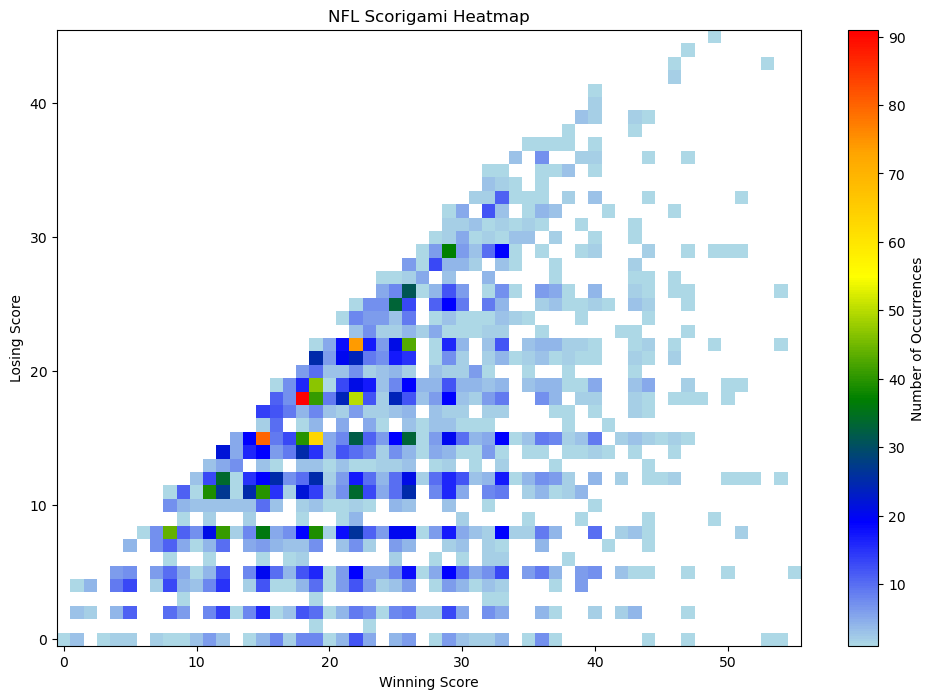

In [73]:
# Run, but do not edit, this cell

plt.figure(figsize=(12, 8))

# Create a color map for our heatplot like the one on nflscorigami.com
from matplotlib.colors import LinearSegmentedColormap
scorigami_colors = ["lightblue", "blue", "green", "yellow", "orange", "red"]
nfl_cmap = LinearSegmentedColormap.from_list("scorigami", scorigami_colors)
# A bit janky - create a new data frame where we put 0's back to nan's, 
# so that we can make sure they are specifically plotted in white
plot_data = scorigami_pivot.replace(0, np.nan)
nfl_cmap.set_bad(color='white')
plt.imshow(plot_data, cmap=nfl_cmap, origin='lower', aspect='auto')

plt.colorbar(label='Number of Occurrences')
plt.xlabel('Winning Score')
plt.ylabel('Losing Score')
plt.title('NFL Scorigami Heatmap')

plt.show()

There are no "boxes" appearing above the diagonal because it is impossible for the losing team's score to be higher than the winning team's score.

**Question 18**: Let's identify the most common pairwise score and how frequently it occurred. Lets do this using `nfl_df`.   Create a new column, `final_score`, that stores the final score as a string `"win score-lose score"`.  E.g. if a game ended with one team scoring 7 points and the other 14, then `final_score` should store the string `14-7`.  Hint: you can  use `.astype(str)` to convert data in your win and losing score columns to strings.  

Then, identify the most frequent game-ending score in this data set, and identify the earliest (least recent) and most recent games in the data set that ended in that score (giving the game date, winning team, and losing team for each).  Is this the same as the most common score in all NFL games (not just the ones in our data set)?  Looking [here](https://nflscorigami.com/) might help!

In [74]:
# Code for Question 18 Here
# Create final_score column
nfl_df["final_score"] = (
    nfl_df["win_score"].astype(str) + "-" + nfl_df["lose_score"].astype(str)
)

# Find most common final score
most_common_score = nfl_df["final_score"].value_counts().idxmax()
score_count = nfl_df["final_score"].value_counts().max()

print(f"Most common final score: {most_common_score} (occurred {score_count} times)")

# Filter games with that score
games_with_score = nfl_df[nfl_df["final_score"] == most_common_score]

# Find earliest and most recent
earliest = games_with_score.loc[games_with_score["date"].idxmin()]
most_recent = games_with_score.loc[games_with_score["date"].idxmax()]

print(f"\nEarliest game: {earliest['date']} - {earliest['win_team']} vs {earliest['lose_team']}")
print(f"Most recent game: {most_recent['date']} - {most_recent['win_team']} vs {most_recent['lose_team']}")

Most common final score: 23-20 (occurred 91 times)

Earliest game: 1/1/2012 - Cardinals vs Seahawks
Most recent game: 9/7/2014 - Bills vs Bears


23-20, but the actual score that I look up is 20-17

### Research Question 4: Zooming in on a Team

Let's zoom in on a single team.  Here are the teams in the data set:

In [75]:
nfl_df["home"].unique()

array(['Giants', 'Bills', 'Bears', 'Bengals', 'Browns', 'Packers',
       'Titans', 'Dolphins', 'Redskins', 'Panthers', 'Jaguars', 'Broncos',
       'Raiders', 'Buccaneers', 'Texans', 'Patriots', 'Falcons',
       'Cowboys', 'Colts', 'Chiefs', 'Saints', 'Jets', 'Ravens', 'Rams',
       'Seahawks', 'Vikings', 'Chargers', '49ers', 'Steelers', 'Eagles',
       'Cardinals', 'Lions'], dtype=object)

Go to [this Google sheet](https://docs.google.com/spreadsheets/d/1KJihSMS0aoVWl3dntnKYwjVerQKPhjYiBLsq-4TEQzw/edit?usp=sharing) and sign up for an NFL team you would like to analyze (see the note at the top of that sheet).

**Question 19**: Let's look at your selected team's overall win rate over time (including both regular season and playoff games).  To do so:
* Create a new DataFrame, `team_df`, that only includes the games from `nfl_df` where your team played 
* Create a new column `win_bin` that is True (if your team won) or False (if your team lost or tied)
* Create a series `team_trend` by grouping `team_df` by `Season`, using a `mean` aggregator, and looking at the `win_bin` column.  This will give the percentage of games your selected team won each season.
* Run the subsequent code cell to plot it!

You do not need to edit any markdown cells for this question.

In [76]:
# Code for Question 19 Here
# You will likely add extra lines

team_name = "Giants"
team_games = nfl_df[(nfl_df["home"] == team_name) | (nfl_df["away"] == team_name)].copy()
team_games["win_bin"] = team_games["win_team"] == team_name
team_trend = team_games.groupby("Season")["win_bin"].mean()

<Axes: title={'center': 'Win Rate for Giants'}, xlabel='Season'>

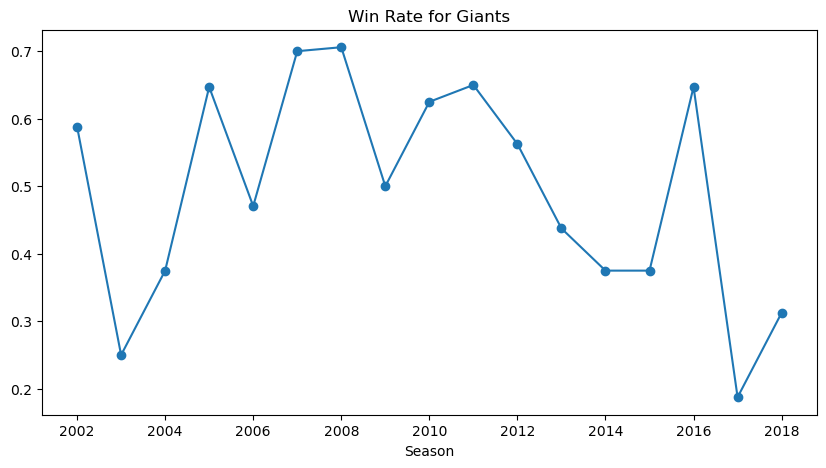

In [77]:
# Run, but do not edit, this cell
team_trend.plot(kind="line", marker="o", figsize=(10, 5), title=f"Win Rate for {team_name}")

**Question 20**: Do you notice any trends over time? In what season did your team have its lowest win rate?  Its highest win rate? Do a bit of research to see what factors might have been at play for each of those seasons (star players, injuries, etc).

Based on the Giants' win trend data, I can provide the following analysis:

**Trends Over Time:**

The Giants showed significant volatility across the 2002-2018 period. Notable patterns include:
- **Peak performance:** 2007-2008 seasons with win rates around 70-71%
- **Lowest performance:** 2017 with a win rate of 18.75% (3-13 record)
- **General decline:** Noticeable downward trend from 2011 onward

**Lowest Win Rate - 2017 (18.75%):**
The 2017 season was catastrophic for the Giants. Key factors included:
- Eli Manning was aging and experiencing one of his worst seasons statistically
- Poor offensive line performance led to increased sacks and quick plays
- The defense struggled significantly, ranking poorly in the NFL
- Head Coach Steve Spagnuolo's tenure was problematic
- The team had minimal offensive weapons after trading away key players

**Highest Win Rate - 2008 (70.59%):**
The 2008 season was the Giants' Super Bowl championship year. Contributing factors:
- Elite defense led by Corey Webster and James Butler
- Eli Manning played exceptionally well in crucial moments
- Strong running game with Brandon Jacobs
- Dominant playoff run culminating in Super Bowl XLII victory over the previously undefeated Patriots
- Cohesive team chemistry and excellent coaching

The data shows that the Giants' success was largely dependent on defensive excellence and Eli Manning's performance during mid-career years, with decline correlating to aging players and roster deterioration in the 2010s.

<hr style="border: 3px solid #003262;" />
 
You have now made it through phase 2!  You are welcome to continue working on the work below, which will be part of phase 3, but you only have to have the above completed for phase 2!

<hr style="border: 3px solid #003262;" />

### Phase 2 Submission Instructions

For Phase 2, you will submit to **two** separate Gradescope assignments: a PDF and your Jupyter notebook.  The same instructions as Phase 1 apply.
1. Restart the Kernel (e.g. Kernel --> Restart) and run all cells above this one (e.g. Cell --> Run All Above). 
2. Make sure that all of the above cells run without error, including the cells that say `# Run, but do not edit, this cell`.  Be sure that you pass the provided tests.
3. Create a PDF of your notebook.  To do so, (1) hit File -> Download as -> HTML (or potentially Save and File -> Export Notebook As -> HTML, depending on your version of Jupyter/OS) (2) open that HTML file in Google Chrome (I drag from downloads into a new Chrome tab), and (3) save that HTML file as a PDF (I type `ctrl+P` to print and then select `Save as PDF` as my destination).  
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.
5. Upload that PDF to `Project 2 Phase 2: PDF Submission` on Gradescope.  Tag all pages with the relevant question, and if you worked with a partner, add them to your submission.
6.  Upload your Project 2 Jupyter notebook to `Project 2 Phase 2: Jupyter Submission` on Gradescope.  If you worked with a partner, add them to your submission.  Look at the code you uploaded and verify that you submitted a complete Jupyter notebook, with answers to the above questions / cells run.  You do not (and should not) zip anything, include data sources, etc -- just upload your .ipynb file.

As always, if you run into any issues, please be sure to send me documentation of your completed work (e.g. a completed Jupyter notebook) before the deadline.

### Phase 2 Grading Information.

Meeting the Phase 2 checkpoint is worth 50 points of your submission.  You will get 2 automatic autograder points for submitting your Jupyter notebook (note that the autograder is only checking that you've included a Jupyter notebook file -- you should independently verify that it actually has the right input and output).  This submission is a backup so that I can see what code was completed on time. 

At this point, I will grade your answers to questions 1-20 on correctness.


<hr style="border: 3px solid #003262;" />
 
## Phase 3: Due Wednesday 3/18 at 10pm

<hr style="border: 3px solid #003262;" />

Note there is a substantial gap between phase 2 and phase 3, since in between we have Midterm 1 and Spring Break!  You may elect to knock this out of the way earlier to avoid having imminent work when we come back from Spring Break!

In this phase, you will focus on two tasks:
* Coming up with your own research question and studying it
* Writing up some of your results in a polished, compelling report

### Step 1: Dig Deeper

First, come up with a research question focussed on the team you studied in Questions 19-20 that uses 2-3 variables.  These can be variables in/attainable from the data set, or ones you merge in (e.g. you could look at what conference/division their opponent was in, and could add this to your `nfl_df` in a variety of ways; you could restrict yourself at home games and use the date to merge something in about the weather (harder but cool), etc).  Don't forget that you have a full data dictionary at the top of the project to remind you of what variables you already have access to!  I'm happy to help brainstorm - and iterating on research questions is an acceptable use of AI (though you probably want to think by yourself first to increase your odds of finding one that's interesting, or to tell AI what you're most interested in in the data set)

Briefly type your research question below: **How actually does the Giants play when they tend to win more?**

For phase 3, I want to study whether the Giants won more when they were more pass-oriented or more rush-oriented.  I will compare the Giants' offensive balance across seasons and see how it lines up with their win rate.

Now use the following cells (adding more as needed) to study your research question.  Add both markdown and code cells that explain your analysis.  This does not need to be super-polished, but should be clear and understandable by anyone in DATA 250.  Along the way, be sure to get at least 1 precise numerical summary (e.g. a mean, median, max, correlation, etc) and 1 graphical summary (e.g. histogram, grouped histogram, boxplot, scatterplot, bar chart, clustered bar chart, etc) with titles/labels/etc that relate to your research question.

As a rough guideline, you should aim to spend about 1.5-2 hours digging into your question -- think about different perspectives, approaches, statistics, and visualizations.  

First, I filter the data down to Giants games and create a few Giants-centered variables.  This lets me compare seasons from the Giants' perspective instead of switching back and forth between home and away columns.

In [78]:
team_name = "Giants"
giants_df = nfl_df[(nfl_df["home"] == team_name)
                    | (nfl_df["away"] == team_name)].copy()

giants_df["team_score"] = np.where(giants_df["home"] == team_name,
                                    giants_df["score_home"],
                                      giants_df["score_away"])

giants_df["opp_score"] = np.where(giants_df["home"] == team_name,
                                   giants_df["score_away"],
                                     giants_df["score_home"])

giants_df["team_pass_yards"] = np.where(giants_df["home"] == team_name,
                                         giants_df["passing_yards_home"], 
                                         giants_df["passing_yards_away"])

giants_df["team_rush_yards"] = np.where(giants_df["home"] == team_name,
                                         giants_df["rushing_yards_home"], 
                                         giants_df["rushing_yards_away"])

giants_df["team_total_yards"] = np.where(giants_df["home"] == team_name,
                                          giants_df["total_yards_home"], 
                                          giants_df["total_yards_away"])

giants_df["win_bin"] = giants_df["win_team"] == team_name
giants_df["pass_share"] = giants_df[
    "team_pass_yards"]/giants_df["team_total_yards"]

giants_df["rush_share"] = giants_df[
    "team_rush_yards"] / giants_df["team_total_yards"]

print("Number of Giants games:", len(giants_df))
print("Seasons covered:", giants_df[
    "Season"].min(), "to", giants_df["Season"].max())
giants_df[["Season", "home", "away", "team_score", "opp_score",
            "team_pass_yards", "team_rush_yards", 
            "pass_share", "rush_share", "win_bin"]].head()

Number of Giants games: 285
Seasons covered: 2002 to 2018


,Season,home,away,team_score,opp_score,team_pass_yards,team_rush_yards,pass_share,rush_share,win_bin
0,2002,Giants,49ers,13,16,318,43,0.880886,0.119114,False
25,2002,Rams,Giants,26,21,291,103,0.738579,0.261421,True
42,2002,Giants,Seahawks,9,6,257,94,0.732194,0.267806,True
55,2002,Cardinals,Giants,7,21,196,67,0.745247,0.254753,False
62,2002,Cowboys,Giants,21,17,212,104,0.670886,0.329114,True


Next, I summarize the Giants by season.  I look at win rate, average passing yards, average rushing yards, and the average share of total yards that came from passing versus rushing.

In [79]:
season_summary = giants_df.groupby("Season").agg(
    win_rate=("win_bin", "mean"),
    avg_pass_yards=("team_pass_yards", "mean"),
    avg_rush_yards=("team_rush_yards", "mean"),
    avg_pass_share=("pass_share", "mean"),
    avg_rush_share=("rush_share", "mean"),
    avg_points=("team_score", "mean")
)

best_season = season_summary["win_rate"].idxmax()
worst_season = season_summary["win_rate"].idxmin()
pass_corr = season_summary["win_rate"].corr(season_summary["avg_pass_share"])
rush_corr = season_summary["win_rate"].corr(season_summary["avg_rush_share"])

print(f"Best Giants season by win rate: {best_season} ({season_summary.
                                    loc[best_season, 'win_rate']:.3f})")
print(f"Worst Giants season by win rate: {worst_season} ({season_summary.
                                    loc[worst_season, 'win_rate']:.3f})")
print(f"Pass share in {best_season}: {season_summary.
                                    loc[best_season, 'avg_pass_share']:.3f}")
print(f"Rush share in {best_season}: {season_summary.
                                    loc[best_season, 'avg_rush_share']:.3f}")
print(f"Pass share in {worst_season}: {season_summary.
                                    loc[worst_season, 'avg_pass_share']:.3f}")
print(f"Rush share in {worst_season}: {season_summary.
                                    loc[worst_season, 'avg_rush_share']:.3f}")
print(f"Correlation between win rate and pass share: {pass_corr:.3f}")
print(f"Correlation between win rate and rush share: {rush_corr:.3f}")

assert ((giants_df["home"] == team_name) | (giants_df["away"] == team_name)).all()
assert season_summary.index.min() == 2002 and season_summary.index.max() == 2018
assert season_summary["win_rate"].between(0, 1).all()

season_summary

Best Giants season by win rate: 2008 (0.706)
Worst Giants season by win rate: 2017 (0.188)
Pass share in 2008: 0.566
Rush share in 2008: 0.434
Pass share in 2017: 0.685
Rush share in 2017: 0.315
Correlation between win rate and pass share: -0.286
Correlation between win rate and rush share: 0.286


,win_rate,avg_pass_yards,avg_rush_yards,avg_pass_share,avg_rush_share,avg_points
Season,,,,,,
2002,0.588235,251.647059,117.294118,0.684515,0.315485,21.058824
2003,0.250000,211.437500,97.437500,0.674054,0.325946,15.187500
2004,0.375000,176.125000,119.000000,0.605690,0.394310,18.937500
2005,0.647059,215.823529,132.352941,0.622016,0.377984,24.823529
2006,0.470588,188.941176,135.705882,0.576363,0.423637,22.058824
2007,0.700000,198.050000,128.150000,0.603389,0.396611,22.900000
2008,0.705882,196.823529,156.235294,0.565833,0.434167,25.764706
2009,0.500000,251.187500,114.812500,0.692968,0.307032,25.125000
2010,0.625000,242.812500,137.500000,0.634663,0.365337,24.625000


Finally, I visualize the trend over time.  The line plot shows how the Giants' win rate moved alongside passing share and rushing share, and the scatterplot helps show whether pass-heavy or rush-heavy seasons matched better with winning.

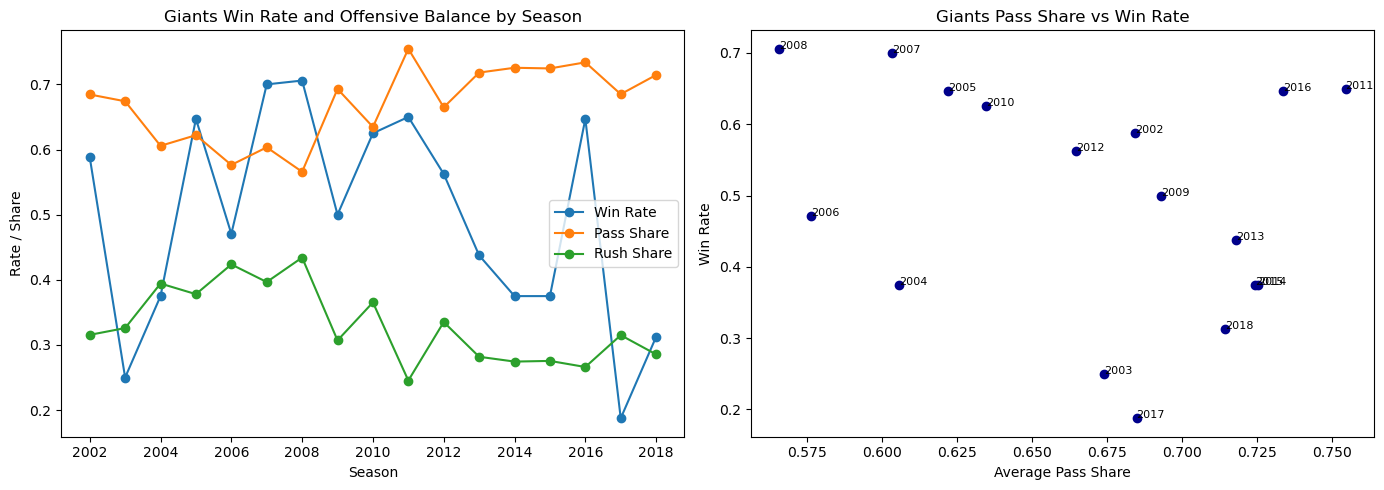

In [80]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(season_summary.index, 
             season_summary["win_rate"], marker="o", label="Win Rate")
axes[0].plot(season_summary.index, 
             season_summary["avg_pass_share"], marker="o", label="Pass Share")
axes[0].plot(season_summary.index, 
             season_summary["avg_rush_share"], marker="o", label="Rush Share")
axes[0].set_title(
    "Giants Win Rate and Offensive Balance by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Rate / Share")
axes[0].legend()

axes[1].scatter(season_summary["avg_pass_share"],
                 season_summary["win_rate"], color="darkblue")
axes[1].set_title("Giants Pass Share vs Win Rate")
axes[1].set_xlabel("Average Pass Share")
axes[1].set_ylabel("Win Rate")

for season in season_summary.index:
    axes[1].annotate(
        season, (season_summary.loc[season, "avg_pass_share"]
                              , season_summary.
                              loc[season, "win_rate"]), fontsize=8)

plt.tight_layout()
plt.show()

The Giants' best season by win rate in this data set was 2008, when they won about 70.6% of their games.  That season was also their most rush-heavy season, with about 43.4% of their yards coming from rushing and about 56.6% from passing.

Their worst season was 2017, when they won only 18.8% of their games.  In that season, the Giants were much less balanced: about 68.5% of their yards came from passing and only about 31.5% came from rushing.

Across seasons, pass share had a correlation of about -0.286 with win rate, while rush share had a correlation of about 0.286 with win rate.  That is not strong enough to say rushing directly caused winning, but it does suggest the Giants tended to do better in seasons where their offense was more balanced and less heavily tilted toward the pass.

In [81]:
season_summary[["win_rate", "avg_pass_yards",
                 "avg_rush_yards", "avg_pass_share", "avg_rush_share"]
               ].sort_values("win_rate", ascending=False)

,win_rate,avg_pass_yards,avg_rush_yards,avg_pass_share,avg_rush_share
Season,,,,,
2008,0.705882,196.823529,156.235294,0.565833,0.434167
2007,0.700000,198.050000,128.150000,0.603389,0.396611
2011,0.650000,293.900000,94.650000,0.754615,0.245385
2016,0.647059,245.529412,87.176471,0.733830,0.266170
2005,0.647059,215.823529,132.352941,0.622016,0.377984
2010,0.625000,242.812500,137.500000,0.634663,0.365337
2002,0.588235,251.647059,117.294118,0.684515,0.315485
2012,0.562500,239.062500,116.375000,0.664817,0.335183
2009,0.500000,251.187500,114.812500,0.692968,0.307032


### Step 2: Communicate Your Results Professionally

In this final step, you will write a 2-4 page polished report for a non-technical audience summarizing your findings about your research question.
* Start with a short introduction.  This should be 1-2 paragraphs and should briefly describe the underlying data and your research question.  Succinctly summarize any findings (e.g. "we find strong evidence to suggest BLAH" or "while one might expect BLAH, we did not find sufficient evidence of BLAH"); this is the "Bottom Line Up Front" method of communication.
* Then get into your research question.  Walk your reader through your analysis and give your results in context.  Be sure to include at least one precise numerical summary and one precise graphical summary.  However, only give statistics relevant to your analysis.  For instance, if you are studying the relationship between two quantitative variables, clearly describing those variables individually and pertinent parts of their distributions may be relevant to your analysis, but you don't want to go crazy into the weeds in doing so: you'd want to ensure you have space to talk about, e.g., a scatterplot/correlation/regression/etc.
* End with a very short paragraph summarizing your findings.  This is already a short report, so you can assume your reader remembers most of what you've said: just give a few sentences recapping your key finding(s).

Notes:
* This should be 2-3 pages including figures/tables using standard Google Docs formatting (size 11 Arial font, 1.15 spacing, normal margins, etc).  Here, 2-3 pages means that your report should end somewhere on the third page.
* Avoid superfluous jargon, be it technical or football related.  If you use terms that a non-technical reader (or reader unfamiliar with football) might not understand, define them in context.  You can assume they know what a mean, median, and standard deviation are, but not much beyond that.
* Any figures/tables should be polished with clear captions and labels.  Use the Chicago Style (details [here](https://sheridancollege.libguides.com/ld.php?content_id=23330161)).
* Remember your statistical reasoning.  Don't assert causation because you identify a correlation.  Avoid language like "we've proved BLAH" since you probably aren't proving anything directly.  Avoid the word "significant" unless you mean it in the precise sense of statistical significance.  Note that you don't need to get any confidence intervals/p-values here (though you are certainly welcome to apply relevant tests and tools from MATH 216/227 if you so desire).
* You should not assume your reader is familiar with the data set.  Give them the context they need *for your research question.*  Going through all the variables in the csv, describing cleaning methods (like splitting columns), etc is probably not worthwhile for your reader.
* In general, aim to be both clear and concise.  Focus on what your reader needs to know to understand your data.  E.g. knowing what years/team you're studying is relevant.  Knowing that you wrote a python function to split columns formatted as strings and containing two different variables is not.
* You don't need to cite the NFL data set and may not need any citations.  If you do want to cite anything, you are welcome to.  Use the Chicago Notes and Bibliography style with shortened notes and a bibliography (details [here](https://www.chicagomanualofstyle.org/tools_citationguide/citation-guide-1.html)).
* Your report should be polished.  Make sure it is well-written, there are not typos, etc.  Revise it early and often, and proofread your final work.  
* You may NOT use AI to write your report for you.  Using a tool like Grammarly is OK, but that's it.  You should not use any LLMs, you should not ask a LLM to critique your writing / rewrite anything for you, etc.


### Phase 3 Submission Instructions

For Phase 2, you will submit to **two** separate Gradescope assignments: a PDF and your Jupyter notebook.  However, this time your PDF should include both your report and a PDF of your Jupyter notebook.  Here are your instructions:
1. Restart the Kernel (e.g. Kernel --> Restart) and run all cells (including from phases 1-2)
2. Make sure that all of the above cells run without error, including the cells that say `# Run, but do not edit, this cell`.  Be sure that you pass the provided tests.  Though this should come for free after phase 2 :).
3. Create a PDF of your notebook, as previously.
4. Skim the PDF and make sure all your code and written responses are fully visible.  If you notice anything (like your code lines are too long and get cut off; your written answers are cut off), fix those issues and repeat the above process. If I cannot see your work, it will not be graded.
5. Save your Google Doc as a PDF.
6. Create a merged PDF including first your 2-3 page report and second your Python notebook.  If you haven't merged PDFs before, google is quite helpful here.  I (on Windows) like to ues an app called PDFsam Basic.
7. Upload that PDF to `Project 2 Phase 3: PDF Submission` on Gradescope.  Tag all pages with the relevant question, and if you worked with a partner, add them to your submission.
8.  Upload your Project 2 Jupyter notebook to `Project 2 Phase 3: Jupyter Submission` on Gradescope.  If you worked with a partner, add them to your submission.  Look at the code you uploaded and verify that you submitted a complete Jupyter notebook, with answers to the above questions / cells run.  You do not (and should not) zip anything, include data sources, etc -- just upload your .ipynb file.

As always, if you run into any issues, please be sure to send me documentation of your completed work (e.g. a completed Jupyter notebook) before the deadline.

### Phase 3 Grading Information.

Your phase 3 grade is worth 35 points on this assignment as follows:
- 20 of the points will be based on your written report
- 10 points will be based on your ``step 1`` work: is it generally correct, did you add enough context in Markdown cells that anyone in DATA 250 could easily follow your work without having to dig into the weeds of your code, did you follow good coding style (comments, split lines, etc)
- 5 points will be based on the depth of your analysis.  This is where you can go above and beyond and move from an A to an A+.  Just selecting two variables in the data set, getting a correlation, and making a scatterplot will likely not get many points here (but you could still get an A on the project if you do so).